# 01 · Data Acquisition & Cleaning

**Project:** NeuroADHD: predicting an ADHD diagnosis with machine learning

This notebook downloads the **ADHD-200** phenotypic (clinical) data, merges the ten scanning sites into one table, and cleans it so the rest of the project starts from a single, trustworthy dataset.

| | |
|---|---|
| **Source** | [ADHD-200 Consortium](http://fcon_1000.projects.nitrc.org/indi/adhd200/), BIDS release on the public INDI S3 bucket |
| **Unit of analysis** | one child or adolescent (ages 7–26) |
| **Target** | clinical diagnosis: ADHD (any subtype) vs. Typically Developing (TD) |
| **Output** | `data/processed/adhd200_clean.csv` |

The ADHD-200 Global Competition (2011) released data from 8 institutions. Each site recorded slightly different variables, rating scales and codes, so most of the work here is **harmonisation**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuroadhd.config import DATA_PROCESSED, DATA_RAW, SITES
from neuroadhd.data import download_raw, load_raw, clean, SCALE_RANGES
from neuroadhd.plotting import savefig, PALETTE, SEQ_BLUE, INK_2, MUTED

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## 1. Download the raw files
One `participants.tsv` per site. Files already on disk are not downloaded again.

In [2]:
paths = download_raw()
for p in paths:
    print(f"{p.name:<32} {p.stat().st_size/1024:6.1f} KB")

participants_Brown.tsv              1.3 KB
participants_KKI.tsv                6.3 KB
participants_NYU.tsv               41.0 KB
participants_NeuroIMAGE.tsv         7.3 KB
participants_OHSU.tsv              14.3 KB
participants_Peking_1.tsv          37.0 KB
participants_Peking_2.tsv          14.7 KB
participants_Peking_3.tsv           9.3 KB
participants_Pittsburgh.tsv        14.7 KB
participants_WashU.tsv              8.8 KB


## 2. Load and inspect the raw tables
Each site uses its own column set, so the raw merge has many sparse columns.

In [3]:
raw = load_raw()
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (1062, 35)


,site,participant_id,gender,age,handedness,verbal_iq,performance_iq,full4_iq,qc_rest_1,qc_anatomical_1,dx,iq_measure,adhd_index,inattentive,hyper_impulsive,qc_rest_2,qc_anatomical_2,full2_iq,disclaimer,qc_rest_3,secondary_dx,adhd_measure,med_status,qc_rest_4,study_#,qc_s1_rest_1,qc_s1_rest_2,qc_s1_rest_3,qc_s1_rest_4,qc_s1_rest_5,qc_s1_rest_6,qc_s1_anat,qc_s2_rest_1,qc_s2_rest_2,qc_s2_anat
0,Brown,26001,Male,16.92,Right,133.0,104.0,120.0,Pass,Pass,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Brown,26002,Male,15.68,Right,106.0,106.0,107.0,Pass,Pass,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Brown,26004,Female,14.99,Right,119.0,123.0,125.0,Pass,Pass,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Brown,26005,Female,15.16,Right,116.0,131.0,126.0,Pass,Pass,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Brown,26009,Male,16.91,Left,113.0,81.0,97.0,Pass,Pass,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


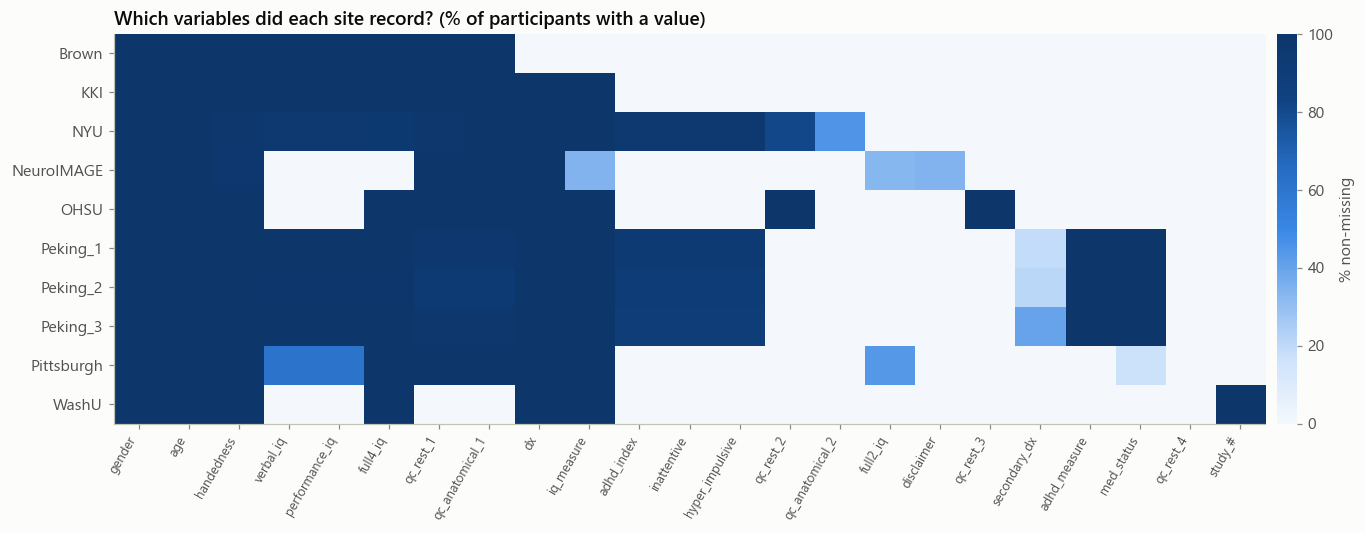

In [4]:
coverage = (raw.groupby("site").apply(lambda g: g.notna().mean(), include_groups=False) * 100).round(0)
keep_cols = [c for c in coverage.columns if c not in ("participant_id",) and not c.startswith("qc_s")]
coverage = coverage[keep_cols]

fig, ax = plt.subplots(figsize=(14, 4.6))
im = ax.imshow(coverage.values, cmap=SEQ_BLUE, aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(keep_cols)), keep_cols, rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(coverage)), coverage.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("% non-missing"); cb.outline.set_visible(False)
ax.set_title("Which variables did each site record? (% of participants with a value)")
savefig(fig, "01_raw_column_coverage"); plt.show()

**Observations**
- **Brown** has no diagnosis column: it was the competition's held-out test site and its labels were never released. Those children cannot be used for supervised learning.
- **Symptom ratings** (`adhd_index`, `inattentive`, `hyper_impulsive`) exist only for **NYU** (Conners' Parent Rating Scale, T-scores) and the three **Peking** sites (ADHD Rating Scale IV, raw scores). The two scales are on different units.
- **Verbal / performance IQ** are missing for OHSU, NeuroIMAGE and WashU, which only report a full-scale IQ.
- `-999` is used as a missing-value code, and `handedness` mixes text (`Right`, `Left`, `L`) with a numeric laterality index.

In [5]:
for col in ["gender", "dx", "handedness", "med_status", "iq_measure"]:
    print(f"--- {col}"); print(raw[col].astype(str).value_counts().head(8).to_string(), "\n")

--- gender
gender
Male      655
Female    406
nan         1 

--- dx
dx
Typically Developing Children    620
ADHD-Combined                    240
ADHD-Inattentive                 162
nan                               26
ADHD-Hyperactive/Impulsive        14 

--- handedness
handedness
Right    729
1.0       32
Left      24
0.91      23
0.82      13
0.83      10
nan        9
0.75       9 

--- med_status
med_status
nan                     748
Medication Naive        196
Medication Na´ve         76
Not Medication Naive     33
Not Medication Na´ve      9 

--- iq_measure
iq_measure
Wechsler Abbreviated Scale of Intelligence (WASI)                     523
Wechsler Intelligence Scale for Chinese Children-Revised (WISCC-R)    296
1                                                                      83
nan                                                                    75
Two subtest WASI                                                       60
Two subtest WISC or WAIS - Block Design and V

## 3. Cleaning and harmonisation
The logic lives in `src/neuroadhd/data.py` so every notebook uses the same rules:

| Step | Rule |
|---|---|
| Missing codes | `-999`, `N/A` and blanks become `NaN` |
| Diagnosis | 4 labels → `dx_label` (TD / ADHD-C / ADHD-I / ADHD-H) and binary target `adhd` |
| Sex | `Male`→1, `Female`→0 |
| Handedness | `Right`→1, `Left`→−1, `Ambidextrous`→0; NYU's numeric laterality index reduced to the dominant hand (its sign), so every site uses the same coding (otherwise handedness leaks the site, see notebook 05) |
| IQ | full-scale IQ = 4-subtest score, falling back to the 2-subtest score; values outside 40–200 removed |
| Symptom ratings | both instruments rescaled to a **0–1 severity** using each scale's theoretical range (no labels used, so no leakage) |
| Medication, comorbidity, scan QC | normalised text flags |
| Duplicates | subjects listed twice in the BIDS release are de-duplicated on `site + participant_id` |

In [6]:
print("Rescaling ranges used for the symptom severity scores:")
pd.DataFrame(SCALE_RANGES).T

Rescaling ranges used for the symptom severity scores:


,adhd_index,inattentive,hyper_impulsive
Conners,"(40, 100)","(40, 100)","(40, 100)"
ADHD-RS,"(18, 72)","(9, 36)","(9, 36)"


In [7]:
dup_rows = (raw["site"] + "_" + raw["participant_id"].astype(str)).duplicated().sum()
print(f"Exact duplicate subject rows in the raw release: {dup_rows}")

df = clean(raw)
print("Clean shape:", df.shape)
df.head()

Exact duplicate subject rows in the raw release: 101
Clean shape: (961, 22)


,site,participant_id,subject_key,dx_label,adhd,sex_male,age,handedness,verbal_iq,performance_iq,full_iq,iq_measure,rating_scale,adhd_index,inattentive,hyper_impulsive,adhd_index_sev,inattentive_sev,hyper_impulsive_sev,med_naive,secondary_dx,qc_rest_pass
0,Brown,26001,Brown_26001,NaN,NaN,1.0,16.92,1.0,133.0,104.0,120.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,Brown,26002,Brown_26002,NaN,NaN,1.0,15.68,1.0,106.0,106.0,107.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,Brown,26004,Brown_26004,NaN,NaN,0.0,14.99,1.0,119.0,123.0,125.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,Brown,26005,Brown_26005,NaN,NaN,0.0,15.16,1.0,116.0,131.0,126.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,Brown,26009,Brown_26009,NaN,NaN,1.0,16.91,-1.0,113.0,81.0,97.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


## 4. Quality checks on the clean table

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 961 entries, 0 to 960
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   site                 961 non-null    object 
 1   participant_id       961 non-null    int64  
 2   subject_key          961 non-null    object 
 3   dx_label             935 non-null    object 
 4   adhd                 935 non-null    float64
 5   sex_male             960 non-null    float64
 6   age                  961 non-null    float64
 7   handedness           952 non-null    float64
 8   verbal_iq            661 non-null    float64
 9   performance_iq       661 non-null    float64
 10  full_iq              899 non-null    float64
 11  iq_measure           803 non-null    object 
 12  rating_scale         477 non-null    object 
 13  adhd_index           477 non-null    float64
 14  inattentive          477 non-null    float64
 15  hyper_impulsive      477 non-null    flo

In [9]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
})
summary

,dtype,missing,missing_%,unique
site,object,0,0.0,10
participant_id,int64,0,0.0,961
subject_key,object,0,0.0,961
dx_label,object,26,2.7,4
adhd,float64,26,2.7,2
sex_male,float64,1,0.1,2
age,float64,0,0.0,519
handedness,float64,9,0.9,3
verbal_iq,float64,300,31.2,71
performance_iq,float64,300,31.2,68


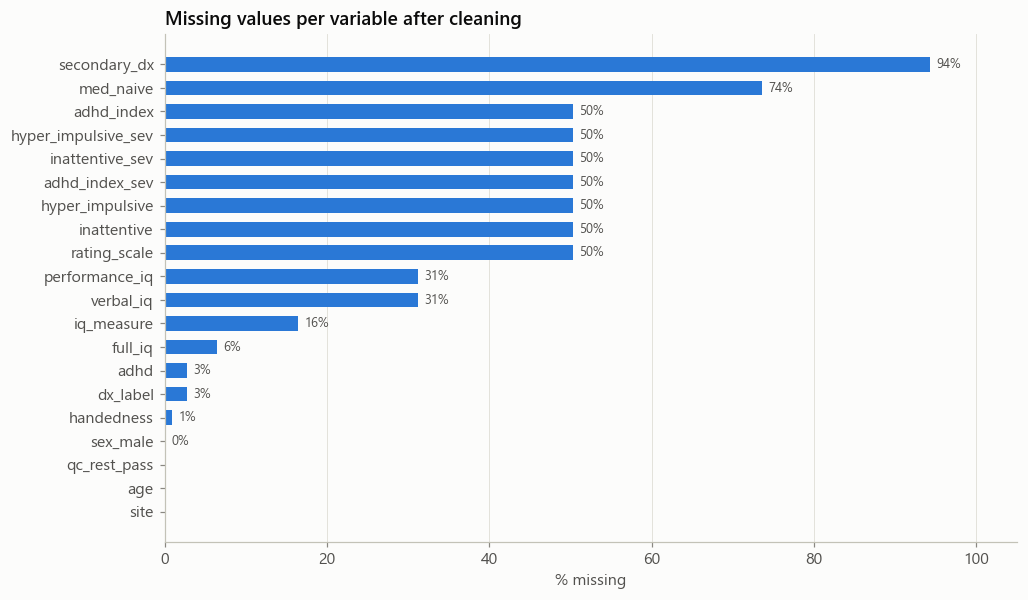

In [10]:
miss = df.drop(columns=["participant_id", "subject_key"]).isna().mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(miss.index, miss.values, color=PALETTE[0], height=0.62)
for b, v in zip(bars, miss.values):
    if v > 0:
        ax.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 105); ax.set_xlabel("% missing"); ax.grid(axis="y", visible=False)
ax.set_title("Missing values per variable after cleaning")
savefig(fig, "01_missing_values"); plt.show()

Missingness is **structured by site**, not random: symptom scores are missing because four sites never collected them, and verbal/performance IQ for the same reason. The preprocessing notebook handles this with (a) separate feature sets and (b) imputation fitted only on training data.

In [11]:
counts = df.assign(dx_label=df["dx_label"].fillna("Unlabelled")).pivot_table(
    index="site", columns="dx_label", values="subject_key", aggfunc="count", fill_value=0)
counts["Total"] = counts.sum(axis=1)
counts.loc["Total"] = counts.sum()
counts

dx_label,ADHD-C,ADHD-H,ADHD-I,TD,Unlabelled,Total
site,,,,,,
Brown,0,0,0,0,26,26
KKI,16,1,5,61,0,83
NYU,99,2,51,111,0,263
NeuroIMAGE,29,6,1,37,0,73
OHSU,27,3,13,70,0,113
Peking_1,16,1,31,88,0,136
Peking_2,15,0,20,32,0,67
Peking_3,7,0,12,23,0,42
Pittsburgh,0,0,4,94,0,98


## 5. Save the analysis dataset
Unlabelled (Brown) children are kept in a separate file: they are useful as an external "unlabelled" set for demonstrating predictions, but they are excluded from training and evaluation.

In [12]:
labelled = df[df["adhd"].notna()].copy()
labelled["adhd"] = labelled["adhd"].astype(int)
unlabelled = df[df["adhd"].isna()].copy()

labelled.to_csv(DATA_PROCESSED / "adhd200_clean.csv", index=False)
unlabelled.to_csv(DATA_PROCESSED / "adhd200_unlabelled.csv", index=False)

print(f"Labelled children : {len(labelled)}  (ADHD {labelled.adhd.sum()}, TD {(labelled.adhd==0).sum()})")
print(f"Unlabelled (Brown): {len(unlabelled)}")
print(f"Prevalence of ADHD in the labelled set: {labelled.adhd.mean():.1%}")

Labelled children : 935  (ADHD 359, TD 576)
Unlabelled (Brown): 26
Prevalence of ADHD in the labelled set: 38.4%


## Summary
- 10 sites merged into **one tidy table**, with duplicates removed and units harmonised.
- Labelled sample: see the counts above. Brown is held out because its diagnoses were never released.
- Two rating instruments were mapped onto a shared 0–1 severity scale.
- Missingness is site-driven, which shapes the modelling strategy in the next notebooks.

**Next:** `02_exploratory_data_analysis.ipynb`